# 01 – Exploration of the raw data

**Project:** The Thin Line Between Melancholy and Rumination: What Happens When We Listen to Sad Music
**Research question:** Who feels better and who feels worse after a memorable experience with sad music – and how do their reasons and feelings differ?

This notebook documents how I explored the raw data, step by step and in the order I did it.
Each step has three parts: **what I did**, the **code**, and **what I found**.
Nothing is changed in the raw data here. Cleaning happens in `02_clean.ipynb`.

**Contents**
0. Setup
1. Load Sample 1 and take a first look
2. Main outcome in Sample 1: `MOODCHANGE`
3. Samples 2 and 3
4. Which file is which sample? (documentation vs. data)
5. Overview of all 131 columns
6. Column index with meanings (labels)
7. The person columns
8. Missing values
9. Column selection
10. Summary, open questions and plan
11. My own contributions and AI usage

## 0. Setup

**Data:** Eerola, T. (2016). *Survey Data on Memorable Experiences with Sad Music – Reasons, Reactions and Mechanisms of Three Types of Experiences.* Harvard Dataverse, V2. https://doi.org/10.7910/DVN/GLSIXB (license: CC0 1.0)
**Related study:** Eerola, T. & Peltola, H.-R. (2016). Memorable Experiences with Sad Music – Reasons, Reactions and Mechanisms of Three Types of Experiences. *PLOS ONE*, 11(6), e0157444. https://doi.org/10.1371/journal.pone.0157444

**Files used** (all in `data/raw/`, downloaded as "Original File Format"):
- `S1_data.csv`, `S2_data.csv`, `S3_data.csv` – the survey answers
- `ASM_label.csv`, `REASON_label.csv`, `FEELING_label.csv`, `PHYS_label.csv`, `MEC_label.csv`, `ESSENTIAL_label.csv` – question texts
- `index.md` – codebook by the author

**How to run:** This notebook lives in `notebooks/`. The data path below goes one folder up (`..`) and into `data/raw/`.
Run all cells from top to bottom ("Run All"), because later cells use variables from earlier cells.
Packages needed: `pandas`, `matplotlib`.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/raw")          # notebooks/ -> one folder up -> data/raw/

pd.set_option("display.max_rows", 200)  # show long tables completely
pd.set_option("display.max_colwidth", 120)

# Same colours in every chart: orange = Worse, grey = Same, blue = Better
MOOD_ORDER = ["Worse", "Same", "Better"]
MOOD_COLORS = ["#eb6834", "#a9a8a1", "#2a78d6"]

## 1. Load Sample 1 and take a first look

**What I did:** I started with the biggest file, `S1_data.csv`, to see how the data is structured.
`.shape` gives (rows, columns), `.head()` shows the first 5 rows.
Other useful commands: `.head(10)` (first 10 rows), `.tail()` (last 5 rows), `.sample(5)` (5 random rows – often more typical than the first rows).

In [2]:
s1 = pd.read_csv(DATA_DIR / "S1_data.csv")   # read the CSV file into a table (DataFrame)
s1.shape                                      # (number of rows, number of columns)

(1577, 131)

In [3]:
s1.head()

,subj,age,gender,listen,expert,listensad,ASM1,ASM2,ASM3,ASM4,...,MEC6,MEC7,MEC8,MEC9,MEC10,MOODCHANGE,PHYSCHANGE,ESSENTIAL1,ESSENTIAL2,ESSENTIAL3
0,1,35 to 44,Female,d,MusicL,Sometimes,6.0,2.0,5.0,3.0,...,1.0,NaN,NaN,1.0,NaN,NaN,NaN,Rarely,Rarely,Sometimes
1,2,45 to 54,Female,mult./d,MusicL,Often,2.0,6.0,6.0,3.0,...,1.0,NaN,NaN,1.0,NaN,Better,Better,Sometimes,Rarely,Very Frequently
2,3,18 to 24,Female,d,NM,Sometimes,6.0,5.0,5.0,5.0,...,NaN,NaN,NaN,NaN,NaN,Same,Better,Frequently,Sometimes,Sometimes
3,4,25 to 34,Male,d,Amat.,Sometimes,5.0,4.0,4.0,6.0,...,1.0,NaN,NaN,1.0,1.0,NaN,NaN,Never,Never,Very Frequently
4,5,25 to 34,Female,mult/w,Amat.,Sometimes,3.0,4.0,5.0,7.0,...,1.0,NaN,NaN,1.0,NaN,Same,NaN,Sometimes,Sometimes,Rarely


**What I found**
- 1,577 rows and 131 columns. One row = one person, one column = one question.
- Many cells are `NaN` (empty). Later I found out that `NaN` does not always mean "missing" (see step 5).
- The data uses abbreviations that differ from the documentation, e.g. `MusicL`, `Amat.`, `NM` in `expert` and `d`, `mult./d` in `listen`.

## 2. Main outcome in Sample 1: `MOODCHANGE`

**What I did:** `MOODCHANGE` answers the question "How was your mood after the episode?" (Worse / Same / Better).
This column is the core of my research question, so I looked at it first.

- `value_counts()` counts how often each answer appears.
- `dropna=False` also counts empty cells (`NaN`). Without it, missing answers would be hidden.
- `normalize=True` gives shares instead of counts.

In [4]:
s1["MOODCHANGE"].value_counts(dropna=False)

MOODCHANGE
Better    959
NaN       366
Same      166
Worse      86
Name: count, dtype: int64

In [5]:
# Percent of ALL people (including missing answers)
s1["MOODCHANGE"].value_counts(normalize=True, dropna=False) * 100

MOODCHANGE
Better    60.811668
NaN       23.208624
Same      10.526316
Worse      5.453393
Name: proportion, dtype: float64

In [6]:
# Percent of the people who ANSWERED (missing answers excluded)
s1["MOODCHANGE"].value_counts(normalize=True) * 100

MOODCHANGE
Better    79.190751
Same      13.707680
Worse      7.101569
Name: proportion, dtype: float64

**First chart.** `reindex()` sets the order Worse → Same → Better (otherwise pandas sorts by frequency).
A chart always needs a title, axis labels and the number of people (`n`).

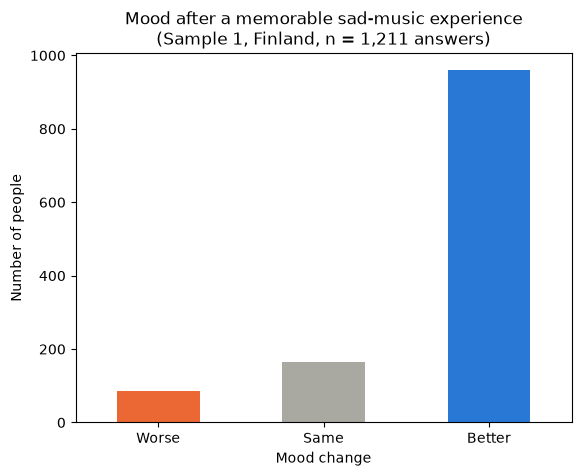

In [7]:
counts = s1["MOODCHANGE"].value_counts().reindex(MOOD_ORDER)
n = counts.sum()

ax = counts.plot(kind="bar", color=MOOD_COLORS)
ax.set_title(f"Mood after a memorable sad-music experience\n(Sample 1, Finland, n = {n:,} answers)")
ax.set_xlabel("Mood change")
ax.set_ylabel("Number of people")
plt.xticks(rotation=0)
plt.show()

**What I found (Sample 1)**
- Of 1,211 people who answered: 79.2% better, 13.7% same, 7.1% worse.
- 366 people (23.2%) did not answer `MOODCHANGE`.
- Lesson: percentages depend on what you divide by – all people or only those who answered. I always state which one I use.
- Sample 1 was recruited through a call in Finnish media, so many participants probably like sad music. This may make the result more positive.

## 3. Samples 2 and 3

**What I did:** I repeated the same steps for `S2_data.csv` and `S3_data.csv`.
To avoid copying the same code three times, the last cell of this step puts all three samples into one comparison table.

In [8]:
s2 = pd.read_csv(DATA_DIR / "S2_data.csv")
s3 = pd.read_csv(DATA_DIR / "S3_data.csv")

print("S1:", s1.shape)
print("S2:", s2.shape)
print("S3:", s3.shape)

S1: (1577, 131)
S2: (414, 131)
S3: (445, 131)


In [9]:
s2.head()

,subj,age,gender,listen,expert,listensad,ASM1,ASM2,ASM3,ASM4,...,MEC6,MEC7,MEC8,MEC9,MEC10,MOODCHANGE,PHYSCHANGE,ESSENTIAL1,ESSENTIAL2,ESSENTIAL3
0,1,35 to 44,Male,mult./d,Amat.,Frequently,2.0,6.0,6,5.0,...,1.0,NaN,NaN,1.0,NaN,Better,Same,Frequently,Frequently,Very Frequently
1,2,18 to 24,Female,mult./d,Amat.,Frequently,2.0,5.0,6,2.0,...,1.0,NaN,NaN,1.0,NaN,NaN,NaN,Rarely,Sometimes,Sometimes
2,3,25 to 34,Male,mult./d,MusicL,Frequently,1.0,6.0,2,3.0,...,1.0,1.0,NaN,1.0,1.0,NaN,NaN,Rarely,Rarely,Very Frequently
3,4,25 to 34,Male,d,NM,Frequently,2.0,6.0,3,3.0,...,1.0,NaN,NaN,1.0,NaN,Better,Same,Rarely,Rarely,Very Frequently
4,5,25 to 34,Male,mult./d,NM,Frequently,1.0,5.0,7,5.0,...,1.0,NaN,NaN,1.0,NaN,Better,Same,Sometimes,Very Frequently,Sometimes


In [10]:
s3.head()

,subj,age,gender,listen,expert,listensad,ASM1,ASM2,ASM3,ASM4,...,MEC6,MEC7,MEC8,MEC9,MEC10,MOODCHANGE,PHYSCHANGE,ESSENTIAL1,ESSENTIAL2,ESSENTIAL3
0,1,35 to 44,Male,NaN,NaN,I don't listen to sad music voluntarily,6,5,4,4,...,NaN,NaN,NaN,NaN,NaN,Same,Better,Sometimes,Rarely,Sometimes
1,2,35 to 44,Male,NaN,NaN,Sometimes,4,5,4,4,...,NaN,1.0,NaN,NaN,NaN,Better,Same,Sometimes,Rarely,Sometimes
2,3,35 to 44,Male,NaN,NaN,Often,3,5,1,6,...,1.0,NaN,NaN,NaN,NaN,NaN,Same,Rarely,Very Frequently,Never
3,4,45 to 54,Male,NaN,NaN,Sometimes,5,5,5,3,...,1.0,NaN,NaN,NaN,NaN,Better,Better,Rarely,Sometimes,Sometimes
4,5,35 to 44,Female,NaN,NaN,Rarely,4,4,4,4,...,1.0,NaN,NaN,NaN,NaN,Better,Better,Never,Rarely,Rarely


In [11]:
samples = {"S1": s1, "S2": s2, "S3": s3}

rows = []
for name, df in samples.items():
    counts = df["MOODCHANGE"].value_counts().reindex(MOOD_ORDER, fill_value=0)
    answered = counts.sum()
    missing = df["MOODCHANGE"].isna().sum()
    row = {"sample": name, "rows": len(df), "answered": answered,
           "missing": missing, "missing %": round(missing / len(df) * 100, 1)}
    for answer in MOOD_ORDER:
        row[f"{answer} % (of answers)"] = round(counts[answer] / answered * 100, 1)
    rows.append(row)

mood_table = pd.DataFrame(rows).set_index("sample")
mood_table

,rows,answered,missing,missing %,Worse % (of answers),Same % (of answers),Better % (of answers)
sample,,,,,,,
S1,1577,1211,366,23.2,7.1,13.7,79.2
S2,414,321,93,22.5,9.3,17.1,73.5
S3,445,362,83,18.7,14.4,47.8,37.8


**What I found**

| Sample | Rows | Answers | Better | Same | Worse | No answer |
|---|---|---|---|---|---|---|
| S1 | 1,577 | 1,211 | 79.2% | 13.7% | 7.1% | 23.2% |
| S2 | 414 | 321 | 73.5% | 17.1% | 9.3% | 22.5% |
| S3 | 445 | 362 | 37.8% | 47.8% | 14.4% | 18.7% |

- S1 and S2 look similar. S3 is very different: "Same" is the most common answer and about twice as many people feel worse.
- In all three samples about 19–23% did not answer `MOODCHANGE`.
- "Worse" in S3 **including** missing answers is 11.7%. This matches a value in the paper, so the authors calculated percentages including missing answers.
- These are first impressions, not statistically tested yet.

## 4. Which file is which sample? (documentation vs. data)

**What I did:** While looking at `s3.head()` I noticed that `listen` and `expert` were empty.
The documentation (`index.md`) says S2 = UK (n = 414) and S3 = Finnish quota (n = 445).
The paper says the UK sample had n = 445 and the Finnish quota sample n = 414, and only the UK sample has no data on musical expertise.
So I checked `expert` and `listen` in S2 and S3.

In [12]:
for col in ["expert", "listen"]:
    for name in ["S2", "S3"]:
        print(f"{name} – {col}")
        print(samples[name][col].value_counts(dropna=False))
        print()

S2 – expert
expert
MusicL      168
Amat.       110
NM          108
Semi-pro     19
Pro           9
Name: count, dtype: int64

S3 – expert
expert
NaN    445
Name: count, dtype: int64

S2 – listen
listen
d          186
mult./d    164
mult/w      45
1-2/mo       8
1/w          7
NaN          4
Name: count, dtype: int64

S3 – listen
listen
NaN    445
Name: count, dtype: int64



**What I found**
- `S3_data.csv` has 445 rows (= UK in the paper).
- `expert` and `listen` are 100% missing in S3 (the paper reports no expertise data only for the UK sample).
- S3 also contains people who say "I don't listen to sad music voluntarily", which fits a representative sample.

**Conclusion:** The labels for S2 and S3 in the documentation are probably swapped. This is likely a labelling error in the documentation, not in my work.
The authors have not confirmed this, so I write "likely".

| File | Sample (likely) | How people were recruited | n |
|---|---|---|---|
| `S1_data.csv` | Finland, convenience | call in Finnish media; whoever wanted took part → many fans of sad music | 1,577 |
| `S2_data.csv` | Finland, quota | selected so that gender and listening to sad music match the UK sample | 414 |
| `S3_data.csv` | UK, representative | matches the UK population in region, age and gender | 445 |

The raw files stay unchanged. The labels are set in `02_clean.ipynb`.

**Terms**
- *Convenience sample:* whoever was easy to reach took part.
- *Quota sample:* fixed shares are set beforehand (e.g. same gender ratio as another group), then people are recruited until the shares are met. Used for fair comparisons.
- *Representative sample:* a small picture of the whole population (age, region, gender).

## 5. Overview of all 131 columns

**What I did:** Before deciding what to use, I wanted to see every column in its original order.
First I checked whether all three files really have the same columns.

In [13]:
list(s1.columns) == list(s2.columns) == list(s3.columns)   # True = same columns in the same order

True

In [14]:
# One row per column of S1: data type, answered, missing, number of different values, examples
overview = pd.DataFrame({
    "column": s1.columns,
    "dtype": s1.dtypes.astype(str).values,
    "non_missing": s1.notna().sum().values,
    "missing": s1.isna().sum().values,
    "unique_values": s1.nunique().values,
    "examples": [s1[c].dropna().unique()[:3].tolist() for c in s1.columns],
})
overview

,column,dtype,non_missing,missing,unique_values,examples
0,subj,int64,1577,0,1577,"[1, 2, 3]"
1,age,str,1577,0,6,"[35 to 44, 45 to 54, 18 to 24]"
2,gender,str,1577,0,2,"[Female, Male]"
3,listen,str,1574,3,6,"[d, mult./d, mult/w]"
4,expert,str,1577,0,5,"[MusicL, NM, Amat.]"
5,listensad,str,1577,0,5,"[Sometimes, Often, Frequently]"
6,ASM1,float64,1575,2,7,"[6.0, 2.0, 5.0]"
7,ASM2,float64,1570,7,7,"[2.0, 6.0, 5.0]"
8,ASM3,float64,1569,8,7,"[5.0, 6.0, 4.0]"
9,ASM4,float64,1569,8,7,"[3.0, 5.0, 6.0]"


**What I found**
- All three files have the same 131 columns (`True`).
- There are only three kinds of questions:
  1. **category** (text), e.g. age group or Worse / Same / Better
  2. **scale 1–7**, e.g. "How pleasurable was the emotion?"
  3. **checkbox**: only one value (`1.0`), everything else `NaN`
- **Important:** in checkbox columns `NaN` means *not ticked*, not *missing*. They must be converted to `0` during cleaning.
  Limitation: "did not tick" and "skipped the question" cannot be told apart.
- In VS Code a long output is shortened ("Output is truncated", `...`). Click "scrollable element" to see all of it.

## 6. Column index with meanings (labels)

**What I did:** The column names (`ASM4`, `FEELING27`, ...) do not say what was asked.
The meanings are in `index.md` and in the `*_label.csv` files (one question text per line, line 1 = item 1).
The label files have no header row, so they are read with `header=None`.

The code below builds one table with all 131 columns: group, question type, meaning, and for each sample:
- for *category*, *scale* and *ID*: % of **missing** answers
- for *checkbox*: % of people who **ticked** the box

Percentages are rounded, the exact count is in brackets. `0% (3)` means 3 people – so "almost nothing", not "nothing".

In [15]:
def read_labels(file_name):
    """Read a label file: one question text per line, no header."""
    return pd.read_csv(DATA_DIR / file_name, header=None)[0].tolist()

labels = {
    "ASM": read_labels("ASM_label.csv"),
    "R": read_labels("REASON_label.csv"),        # 24 lines -> fits R1-R24 (see note below)
    "FEELING": read_labels("FEELING_label.csv"),
    "PHYS": read_labels("PHYS_label.csv"),
    "MEC": read_labels("MEC_label.csv"),
    "ESSENTIAL": read_labels("ESSENTIAL_label.csv"),
}
{group: len(texts) for group, texts in labels.items()}   # number of labels per file

{'ASM': 25, 'R': 24, 'FEELING': 36, 'PHYS': 5, 'MEC': 10, 'ESSENTIAL': 3}

In [16]:
# Single columns: (group, type, meaning) – meanings from index.md
single_columns = {
    "subj": ("Person", "ID", "Unique participant ID"),
    "age": ("Person", "category", "Age group (18 to 24 ... 75 or older)"),
    "gender": ("Person", "category", "Gender (Female, Male)"),
    "listen": ("Person", "category", "How often do you listen to music? (1-2/y, 1-2/mo, 1/w, mult/w, d = daily, mult./d = several times a day)"),
    "expert": ("Person", "category", "Musical expertise (NM = non-musician, MusicL = music lover, Amat. = amateur, Semi-pro, Pro)"),
    "listensad": ("Person", "category", "How often do you listen to sad music? (Frequently ... I don't listen to sad music voluntarily)"),
    "AGO": ("Episode", "category", "How long ago was the memorable experience? (less than a day ... over a year)"),
    "CHOICE": ("Episode", "category", "Was the music self-chosen? (Self-chosen, Not self-chosen)"),
    "FAM": ("Episode", "category", "How familiar was the music? (unfamiliar ... extremely familiar)"),
    "IMPORTANCE": ("Episode", "category", "How autobiographically important was the music? (Not at all ... Extremely Important)"),
    "DURATION": ("Episode", "category", "How long did the episode last? (<5min ... 60 min+)"),
    "INTENSITY": ("Episode", "scale 1-7", "How intense was the emotion? (1 = not at all, 7 = extremely)"),
    "PLEASURE": ("Episode", "scale 1-7", "How pleasurable was the emotion? (1 = not at all, 7 = extremely)"),
    "MOODCHANGE": ("After", "category", "How was your mood after the episode? (Worse, Same, Better)"),
    "PHYSCHANGE": ("After", "category", "How was your physical state after the episode? (Worse, Same, Better)"),
}

# Item groups: prefix -> (group, type). Order matters: "REASON" must be checked before "R".
item_groups = {
    "ASM": ("Attitudes towards sad music (general)", "scale 1-7"),
    "REASON": ("Reason in this episode", "checkbox"),
    "FEELING": ("Feeling in this episode", "checkbox"),
    "PHYS": ("Physical reaction in this episode", "checkbox"),
    "MEC": ("Mechanism in this episode", "checkbox"),
    "ESSENTIAL": ("How often in general (Never ... Very Frequently)", "category"),
    "R": ("Reasons for listening to sad music (general)", "checkbox"),
}

def describe_column(col):
    """Return group, type and meaning of a column."""
    if col in single_columns:
        return single_columns[col]
    for prefix, (group, col_type) in item_groups.items():
        number = col[len(prefix):]
        if col.startswith(prefix) and number.isdigit():
            if prefix == "REASON":
                return group, col_type, "label unknown (not in the data release)"
            return group, col_type, labels[prefix][int(number) - 1]

def sample_info(df, col, col_type):
    """Checkbox: % ticked. Everything else: % missing. Count in brackets."""
    if col_type == "checkbox":
        value = df[col].notna().sum()
    else:
        value = df[col].isna().sum()
    return f"{value / len(df):.0%} ({value})"

rows = []
for i, col in enumerate(s1.columns):
    group, col_type, meaning = describe_column(col)
    row = {"#": i, "column": col, "group": group, "type": col_type, "meaning": meaning}
    for name, df in samples.items():
        row[name] = sample_info(df, col, col_type)
    rows.append(row)

column_index = pd.DataFrame(rows).set_index("#")
column_index

,column,group,type,meaning,S1,S2,S3
#,,,,,,,
0,subj,Person,ID,Unique participant ID,0% (0),0% (0),0% (0)
1,age,Person,category,Age group (18 to 24 ... 75 or older),0% (0),0% (0),0% (0)
2,gender,Person,category,"Gender (Female, Male)",0% (0),0% (0),0% (0)
3,listen,Person,category,"How often do you listen to music? (1-2/y, 1-2/mo, 1/w, mult/w, d = daily, mult./d = several times a day)",0% (3),1% (4),100% (445)
4,expert,Person,category,"Musical expertise (NM = non-musician, MusicL = music lover, Amat. = amateur, Semi-pro, Pro)",0% (0),0% (0),100% (445)
5,listensad,Person,category,How often do you listen to sad music? (Frequently ... I don't listen to sad music voluntarily),0% (0),0% (0),0% (0)
6,ASM1,Attitudes towards sad music (general),scale 1-7,F2-10 I listen to sad music only in a certain state of mind,0% (2),0% (1),0% (0)
7,ASM2,Attitudes towards sad music (general),scale 1-7,F3-11 Listening to sad music relaxes me,0% (7),0% (1),0% (0)
8,ASM3,Attitudes towards sad music (general),scale 1-7,F3-14 I regulate my own negative feelings by listening to sad music,1% (8),0% (0),0% (0)


**What I found**
- **`REASON1–REASON13` have no labels.** `index.md` says `REASON_label.csv` belongs to `REASON1–13` (13 items), but it also says `R1–R24` use `REASON_label.csv`.
  The file has **24 lines**, so it fits `R1–R24`. The most ticked `R` items (beautiful, listening alone, comfort, reminiscing) match the top reasons in the paper, which supports this.
  The release notes PDF says the same as `index.md`. So the 13 question texts for `REASON1–13` are not included in the data release.
- **Real gaps** exist almost only in `MOODCHANGE` and `PHYSCHANGE` (about 16–24% in all samples). All other questions are almost complete.
- **S3:** `listen` and `expert` 100% missing, `INTENSITY` 16% missing.
- `index.md` has small errors (e.g. "ESSENTIAL1-ESSENTIAL10" instead of 1–3).

## 7. The person columns

**What I did:** I looked at the answers of the person columns in all three samples and compared the abbreviations with `index.md`.

In [17]:
for col in ["age", "gender", "listen", "listensad"]:
    table = pd.DataFrame({name: df[col].value_counts(dropna=False) for name, df in samples.items()})
    print(col)
    print(table.fillna(0).astype(int))
    print()

age
              S1   S2   S3
age                       
18 to 24     356   80   41
25 to 34     498  122   77
35 to 44     332   90  100
45 to 54     213   65  114
55 to 64     137   41  101
65 to 74      41   16   10
75 or older    0    0    2

gender
          S1   S2   S3
gender                
Female  1171  209  237
Male     406  205  208

listen
          S1   S2   S3
listen                
1-2/mo    25    8    0
1-2/y      3    0    0
1/w       27    7    0
d        675  186    0
mult./d  680  164    0
mult/w   164   45    0
NaN        3    4  445

listensad
                                          S1   S2   S3
listensad                                             
Frequently                               350   40   42
I don't listen to sad music voluntarily   14   21   44
Often                                    535   84   90
Rarely                                    68   75   69
Sometimes                                610  194  200



**What I found**
- `age`: most people in S1 are 25–34; only few are over 65.
- `gender`: S1 is 74% female (1,171 of 1,577) – an imbalance to keep in mind.
- `listen` abbreviations (from `index.md`): `1-2/y` = 1–2 times a year, `1-2/mo` = 1–2 times a month, `1/w` = once a week, `mult/w` = several times a week, `d` = daily, `mult./d` = several times a day.
- `listensad`: S3 contains more people who rarely or never listen to sad music voluntarily.

## 8. Missing values

**What I did:** I asked myself when missing values are "a lot". There is no fixed rule. Rules of thumb: from about 5% worth noting, from about 20% a serious issue.
More important is to compare a column with its neighbours and to ask *why* data is missing.
The table below shows only category and scale columns (checkboxes excluded, because there `NaN` means "not ticked") with more than 5% missing in at least one sample.

In [18]:
not_checkbox = column_index[column_index["type"] != "checkbox"]["column"]

missing_pct = pd.DataFrame({name: df[not_checkbox].isna().mean() * 100 for name, df in samples.items()}).round(1)
missing_pct[(missing_pct > 5).any(axis=1)]

,S1,S2,S3
listen,0.2,1.0,100.0
expert,0.0,0.0,100.0
INTENSITY,0.9,1.0,16.0
MOODCHANGE,23.2,22.5,18.7
PHYSCHANGE,24.5,22.5,16.4


**What I found**
- `MOODCHANGE` and `PHYSCHANGE` are missing in about 16–24% of all samples, while the questions before and after are almost complete.
  So people did not simply stop the survey. The reason is unknown (open question).
- `listen` and `expert` are 100% missing in S3, `INTENSITY` 16% in S3.

## 9. Column selection

**How I decided:** For every column I asked:
1. What does it mean? (`index.md` and label files)
2. Is it complete in all three samples?
3. Does it help to answer my research question?

### Selected

| Columns | Meaning | Why I include it |
|---|---|---|
| `subj` | participant ID | only to count people |
| `age`, `gender` | age group, gender | to describe and compare participants |
| `listen` | how often people listen to music | general music habits (missing in S3) |
| `listensad` | how often people listen to sad music | key for the difference between people who like sad music and people who don't |
| `ASM1–ASM25` | attitudes towards sad music (1–7) | e.g. `ASM3` "I regulate my own negative feelings..." vs. `ASM4` "Sad music intensifies my own negative feelings" – close to melancholy vs. rumination |
| `R1–R24` | general reasons for listening to sad music | *why* people listen (comfort, reminiscing, beauty, ...) |
| `CHOICE` | self-chosen music or not | did people choose sad music on purpose? |
| `FAM` | familiarity of the music | familiar music is linked to memories |
| `IMPORTANCE` | personal importance of the music | personal meaning |
| `DURATION` | length of the episode | strength of the experience; maybe a link to neuroscience data later |
| `FEELING1–FEELING36` | feelings during the experience | which feelings come with sad music |
| `INTENSITY`, `PLEASURE` | strength and pleasantness (1–7) | how strong and how pleasant (note: `INTENSITY` 16% missing in S3) |
| `PHYS1–PHYS5` | physical reactions | the body's reaction (chills, crying) |
| `MEC1–MEC10` | mechanisms | *how* the music caused the feeling (memories, beauty, ...) |
| `MOODCHANGE` | mood after the experience | **main outcome** of my research question |

### To decide
| Columns | Meaning | Thoughts |
|---|---|---|
| `AGO` | how long ago the experience was | control variable: memories change over time (in the paper, 42% were more than a year ago) |
| `PHYSCHANGE` | physical state after the experience | adds the body's side to `MOODCHANGE` |
| `ESSENTIAL1–3` | how often people feel 1) grief/loss, 2) depression/gloom/sadness, 3) relief/comfort/joy with sad music | fits the "thin line": comfort vs. a pull downwards |

### Excluded
| Columns | Why |
|---|---|
| `expert` | 100% missing in S3 → no fair comparison. Note: the paper found differences by musical expertise, so this is a limitation. |
| `REASON1–REASON13` | no labels in the data release → cannot be interpreted |

### Overlaps between columns
Some topics appear twice: once in general and once in the specific experience. They are not shown in one chart, but can be compared later.

| Topic | General | In the experience |
|---|---|---|
| comfort | `R8` "to comfort me" | `FEELING32` "comfort" |
| memories | `R10` "reminisce", `ASM19` | `MEC3` "memories" |
| regulating feelings | `ASM3`, `R12` "channel my emotions" | `MOODCHANGE` |
| relaxing | `ASM2`, `R9` | `FEELING23` "peacefulness" |
| sadness / depression | `ESSENTIAL2` | `FEELING4` "sadness", `FEELING29` "depression" |

## 10. Summary, open questions and plan

### Decisions
- **Samples are shown separately, never pooled.** They differ strongly (79% vs. 38% better), and S1 would dominate a pooled result (65% of all people).
  Different sample sizes are handled with **percentages within each sample**; the size only affects precision (roughly ±5 percentage points at n ≈ 400, ±2–3 at n ≈ 1,500).
- Always show **n**.
- Comparisons focus on **Better vs. Worse** in `MOODCHANGE`.
- The focus is the human experience, not nationality. Country and recruitment are treated as possible **confounders** (factors that may influence the result without being the research question).

### Open questions
1. Why is `MOODCHANGE` missing so often (about 20%)?
2. Is the difference between S1/S2 (Finland, 74–79% better) and S3 (UK, 38% better) due to recruitment, translation of the question, culture or chance?
3. Are the S2/S3 labels in the documentation really swapped? (likely, not confirmed)

### Limitations (so far)
- Retrospective self-reports (people remember one experience) → no cause and effect
- Rumination was not measured directly → "Worse" is only a hint at a downward spiral
- Samples differ in country, recruitment and size
- About 20% missing in `MOODCHANGE`
- `expert` and `REASON1–13` cannot be used
- Checkbox `NaN`: "not ticked" and "skipped" cannot be told apart
- The "Worse" groups are small (S1: 86, S2: 30, S3: 52) → differences are hints, not proof

### Cleaning plan (`02_clean.ipynb`)
1. Load `S1_data.csv`, `S2_data.csv`, `S3_data.csv` (raw files stay unchanged)
2. Add a column `sample`: `S1_Finland_convenience`, `S2_Finland_quota`, `S3_UK_representative`
3. Check that answer values are spelled the same in all samples (e.g. `Better`, `Same`, `Worse`)
4. Combine the three files into one table (`pd.concat`), keeping `sample`
5. Keep only the selected columns (drop `expert`, `REASON1–13`)
6. Checkbox columns (`R`, `FEELING`, `PHYS`, `MEC`): replace `NaN` with `0`
7. Rename abbreviated values (e.g. `mult./d` → `several times a day`)
8. Set the order of categories (Worse → Same → Better, 18 to 24 → 75 or older, ...)
9. Do not fill missing values in `MOODCHANGE`: keep them as `NaN` and report them
10. Save as `data/processed/sad_music_clean.csv`

### Analysis plan (`03_analysis.ipynb`)
- `MOODCHANGE` per sample (counts and %)
- Better vs. Worse: compare feelings, reasons, attitudes and the situation
- Simple statistics to check whether differences could be chance

### Chart plan (`04_visualize.ipynb`)
Rules: percentages, n in every chart, same colours (orange = Worse, grey = Same, blue = Better), horizontal bars for long labels, samples shown separately.

| # | Chart | Type | y-axis | x-axis |
|---|---|---|---|---|
| 1 | Main result: mood and body after the experience | 100% stacked bars, 2 panels | sample | % Worse / Same / Better |
| 2 | Who took part? | 4 small panels, grouped bars | % of people | categories of `age`, `gender`, `listen`, `listensad` |
| 3 | Listening to sad music vs. mood after | 100% stacked bars | `listensad` | % Worse / Same / Better |
| 4 | Feelings: Worse vs. Better | dumbbell | `FEELING` items, sorted by gap | % ticked |
| 5 | Reasons: Worse vs. Better | dumbbell | `R` items | % ticked |
| 6 | Attitudes: Worse vs. Better | dumbbell | `ASM` items | average 1–7 |
| 7a | The situation | small 100% stacked bars | Worse / Better | % per category of `CHOICE`, `FAM`, `IMPORTANCE`, `DURATION` |
| 7b | The reaction | dumbbell | `PHYS`, `MEC`, `INTENSITY`, `PLEASURE` | % ticked / average 1–7 |

A dumbbell chart shows two dots per row (Worse and Better) connected by a line. The longer the line, the bigger the difference.

### Roadmap
| Phase | Task | Status |
|---|---|---|
| 0 | Topic, sources, data, license, repo | done |
| 1 | Explore: understand the data, select columns | done (open: `AGO`, `PHYSCHANGE`, `ESSENTIAL`) |
| 2 | Clean | next |
| 3 | Analysis | open |
| 4 | Visualize | open |
| 5 | Document: main README, `AI_USAGE.md`, limitations, make repo public | open |

## 11. My own contributions and AI usage

### Ideas and decisions that came from me
- Chose the topic (sad music, emotion regulation, melancholy vs. rumination) and the project title
- Recognised that streaming data (e.g. Spotify) is not suitable, because it does not show whether people listened consciously or how they felt
- Found sources myself on PubMed Central and OSF (e.g. Taruffi et al. 2017, Garrido & Schubert 2013)
- Asked *why* before running code (e.g. why only 5 rows with `.head()`, what `data/processed/` is for)
- Pointed out that the samples must be treated differently, and that missing answers must not be ignored
- Decided to explore S1, S2 and S3 separately and to show them separately
- Questioned the unequal sample sizes
- Selected the columns and decided which ones to exclude
- Decided to focus on the human experience, not nationality

### What I did myself
- Downloaded the data from Harvard Dataverse and checked the license (CC0)
- Set up the repo structure (`data/raw/`, `data/processed/`, `notebooks/`, README files)
- Ran all code myself and checked every output
- Created the first chart and compared S1, S2 and S3

### Where AI helped (Claude, Anthropic)
- Explaining concepts (licenses, sampling, missing values, chart types) and research findings
- Suggesting code step by step and explaining each line
- Pointing out errors (e.g. `s2` instead of `s3` in a cell)
- Spotting the hint in the paper (Table 5) that S2 and S3 might be swapped – I then checked it with the data
- Generating the column index (step 6) from `index.md` and the label files
- Restructuring this notebook into a clean, chronological version
- Most of the code was written by Claude based on my instructions; I ran it and checked every result.

### What I want to improve
- Double-check variable and file names after copying code
- Spot contradictions between data and documentation on my own

## 12. Outlook: from self-reports to the brain

This dataset contains **self-reports**: people describe how they felt when they remember a past experience with sad music.
Self-reports are subjective. They show how people *experience and remember* their feelings, but not what happens in the brain or body.

This project is my first attempt to approach the topic with data.
After finishing the survey analysis, I would like to **search for open neuroscience data** (e.g. EEG or fMRI recorded while people listen to sad music).
I have not selected a dataset yet. The goal would be to see whether patterns from the survey also show up in the brain – for example:
- Does sad music activate networks linked to self-focused thinking (e.g. the default mode network)?
- Is there a difference in brain activity between people who feel better and people who feel worse after sad music?

Note: brain data would come from different people and different situations than this survey. It could add a new perspective, but it cannot directly prove what happened in the survey participants.